# Random Forest Extension: UFC fight outcomes

## Question

Can pre-fight fighter records predict whether the Red or Blue corner wins? The reference study is McQuaide (2019), *Applying Machine Learning Algorithms to Predict UFC Fight Outcomes*. Its original dataset link is unavailable, so this project uses the public TidyTuesday UFC dataset and restricts it to 2010–2019.

## How this model works

A Random Forest trains many decision trees on bootstrapped samples and random subsets of features, then combines their votes. Averaging many diverse trees usually reduces the instability of one deep tree.

### Why include it

Random Forest is not one of the reference models. It provides a tree-ensemble comparison that captures nonlinear effects and interactions without building trees sequentially.

### Settings used

300 trees; minimum leaf size 3; balanced subsampling by class; random seed 42.

## Shared evaluation design

Each notebook uses the same 48 pre-fight fighter fields, date ordering, 20 expanding-window time-series folds, and preprocessing as the main project. Each test fold occurs after its training data. Numeric gaps are filled with the training-fold median, stances are one-hot encoded, and features are scaled inside the fold. No-contests are excluded. The selected years have no draws.

The saved tables below let you inspect the completed run immediately. Run the code cells to reproduce the results on your machine.


## Saved run results

These are the results from the completed 20-fold chronological run. The next cells rerun this model from the bundled dataset. Accuracy is the share of bouts assigned to the correct corner. Macro-F1 computes F1 separately for Red and Blue, then averages the two scores equally.

| Measure | Result |
|---|---:|
| Mean training accuracy | 99.3% |
| Mean test accuracy | 58.2% |
| Test accuracy standard deviation across folds | 3.4% |
| Mean test macro-F1 | 0.531 |
| Paper test accuracy | Not reported in the paper |
| Difference from paper | — |

The always-Red baseline is 58.2% accuracy on this slice. This period contains 4,073 bouts: 2,372 Red wins and 1,701 Blue wins. It contains no draws, so results here are binary despite the reference paper's three-outcome task.

![Twenty chronological test-fold accuracies](../results/plots/05_random_forest_extension_accuracy.png)

### Fold-by-fold results

| Fold | Train accuracy | Test accuracy | Test macro-F1 |
|---:|---:|---:|---:|
| 1 | 99.1% | 49.7% | 0.491 |
| 2 | 98.0% | 56.5% | 0.516 |
| 3 | 98.7% | 56.0% | 0.493 |
| 4 | 99.0% | 60.6% | 0.545 |
| 5 | 99.4% | 52.3% | 0.458 |
| 6 | 99.4% | 57.0% | 0.500 |
| 7 | 99.5% | 57.5% | 0.528 |
| 8 | 99.6% | 63.2% | 0.560 |
| 9 | 99.5% | 59.1% | 0.536 |
| 10 | 99.6% | 63.7% | 0.577 |
| 11 | 99.5% | 56.0% | 0.474 |
| 12 | 99.4% | 55.4% | 0.465 |
| 13 | 99.4% | 58.5% | 0.532 |
| 14 | 99.4% | 60.1% | 0.570 |
| 15 | 99.3% | 60.6% | 0.574 |
| 16 | 99.4% | 59.6% | 0.577 |
| 17 | 99.4% | 57.0% | 0.530 |
| 18 | 99.5% | 60.6% | 0.581 |
| 19 | 99.6% | 59.6% | 0.577 |
| 20 | 99.6% | 60.6% | 0.527 |

**How to read this model's result:** The extension ties Gradient Boosting on mean test accuracy and has higher mean macro-F1, but its very high training accuracy shows substantial overfitting. It does not improve accuracy over the paper reproduction.


In [1]:
from pathlib import Path
import sys
from IPython.display import display
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import TimeSeriesSplit

search_paths = [Path.cwd(), *Path.cwd().parents]
project_root = next((path for path in search_paths if (path / "src" / "train.py").is_file()), None)
if project_root is None:
    raise FileNotFoundError("Open the UFC project folder in VS Code so the notebook can locate src/train.py.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.train import N_SPLITS, load_data, make_models, make_pipeline

data, X, y = load_data()
model_name = 'Random forest (extension)'
model = make_models()[model_name]
print(f"Loaded {len(data):,} bouts from {data['date'].min().date()} to {data['date'].max().date()}")
print("Outcome counts:")
display(y.value_counts().rename_axis("corner").to_frame("bouts"))

Loaded 4,073 bouts from 2010-03-21 to 2019-12-21
Outcome counts:


,bouts
corner,
Red,2372
Blue,1701


In [2]:
fold_rows = []
splitter = TimeSeriesSplit(n_splits=N_SPLITS)

for fold, (train_idx, test_idx) in enumerate(splitter.split(X), start=1):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    pipeline = make_pipeline(model)
    pipeline.fit(X_train, y_train)
    train_prediction = pipeline.predict(X_train)
    test_prediction = pipeline.predict(X_test)
    fold_rows.append({
        "fold": fold,
        "train_rows": len(train_idx),
        "test_rows": len(test_idx),
        "train_accuracy": accuracy_score(y_train, train_prediction),
        "test_accuracy": accuracy_score(y_test, test_prediction),
        "test_macro_f1": f1_score(y_test, test_prediction, average="macro", zero_division=0),
    })

fold_results = pd.DataFrame(fold_rows)
summary = pd.DataFrame([{
    "model": model_name,
    "mean_train_accuracy": fold_results["train_accuracy"].mean(),
    "mean_test_accuracy": fold_results["test_accuracy"].mean(),
    "test_accuracy_sd": fold_results["test_accuracy"].std(),
    "mean_test_macro_f1": fold_results["test_macro_f1"].mean(),
}])
display(summary.style.format({
    "mean_train_accuracy": "{:.1%}",
    "mean_test_accuracy": "{:.1%}",
    "test_accuracy_sd": "{:.1%}",
    "mean_test_macro_f1": "{:.3f}",
}))
display(fold_results.style.format({
    "train_accuracy": "{:.1%}",
    "test_accuracy": "{:.1%}",
    "test_macro_f1": "{:.3f}",
}))

,model,mean_train_accuracy,mean_test_accuracy,test_accuracy_sd,mean_test_macro_f1
0,Random forest (extension),99.3%,58.1%,3.4%,0.531


,fold,train_rows,test_rows,train_accuracy,test_accuracy,test_macro_f1
0,1,213,193,99.1%,51.8%,0.511
1,2,406,193,98.0%,56.0%,0.505
2,3,599,193,98.7%,54.9%,0.481
3,4,792,193,99.0%,58.0%,0.517
4,5,985,193,99.6%,54.4%,0.490
5,6,1178,193,99.5%,59.1%,0.524
6,7,1371,193,99.5%,53.9%,0.482
7,8,1564,193,99.7%,64.2%,0.581
8,9,1757,193,99.5%,58.5%,0.543
9,10,1950,193,99.5%,62.2%,0.572


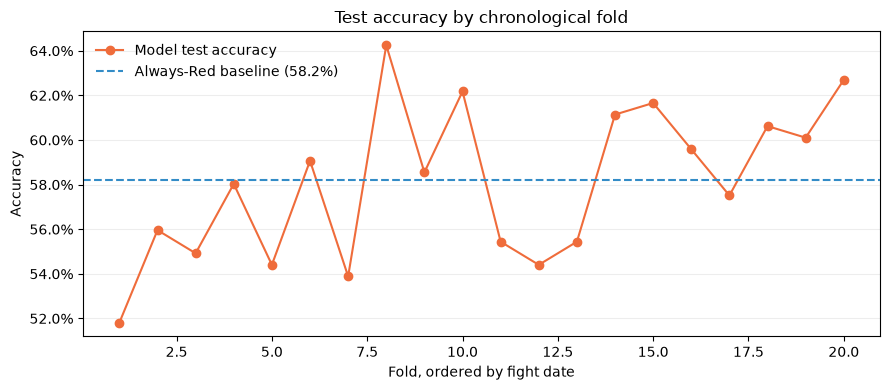

In [3]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(fold_results["fold"], fold_results["test_accuracy"], marker="o", color="#ef6c3b", label="Model test accuracy")
ax.axhline(0.582, color="#338cc7", linestyle="--", label="Always-Red baseline (58.2%)")
ax.set(title="Test accuracy by chronological fold", xlabel="Fold, ordered by fight date", ylabel="Accuracy")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(axis="y", alpha=0.22)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## Interpretation

The extension ties Gradient Boosting on mean test accuracy and has higher mean macro-F1, but its very high training accuracy shows substantial overfitting. It does not improve accuracy over the paper reproduction.

The reference scores are not a like-for-like benchmark because its original sample spans 1997–2019, has 134 features, and includes three outcomes. This dataset starts in 2010 and the selected slice has only Red and Blue outcomes. Treat the paper comparison as approximate.

**Sources:** [McQuaide (2019) report](https://cs229.stanford.edu/proj2019aut/data/assignment_308832_raw/26647731.pdf) · [TidyTuesday dataset documentation](https://github.com/rfordatascience/tidytuesday/tree/main/data/2026/2026-07-07)
